In [ ]:
pip install CatBoost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.2 MB/s eta 0:00:00


In [ ]:
# ==============================
# 1. IMPORTS
# ==============================
import pandas as pd
import numpy as np

from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.metrics import *

from catboost import CatBoostClassifier

import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# ==============================
# 2. LOAD DATA
# ==============================
df = pd.read_csv("/content/Churn_Modelling.csv")

In [ ]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [ ]:
df.isnull().sum()

,0
RowNumber,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0


In [ ]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [ ]:
# Drop unnecessary columns
df.drop(columns=["RowNumber", "CustomerId", "Surname"], inplace=True)

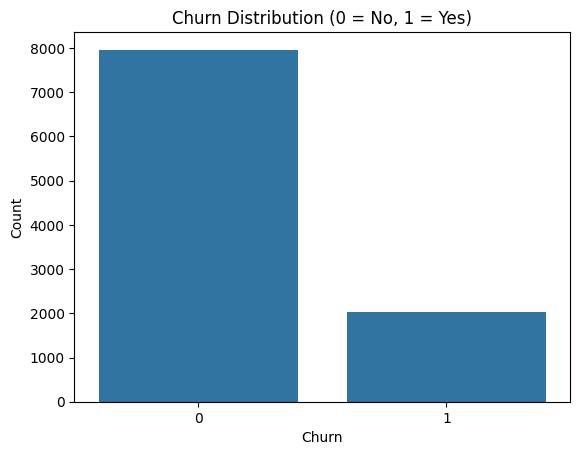

In [ ]:
# ------------------------------
# 1. TARGET DISTRIBUTION
# ------------------------------
plt.figure()
sns.countplot(x="Exited", data=df)
plt.title("Churn Distribution (0 = No, 1 = Yes)")
plt.xlabel("Churn")
plt.ylabel("Count")
plt.show()

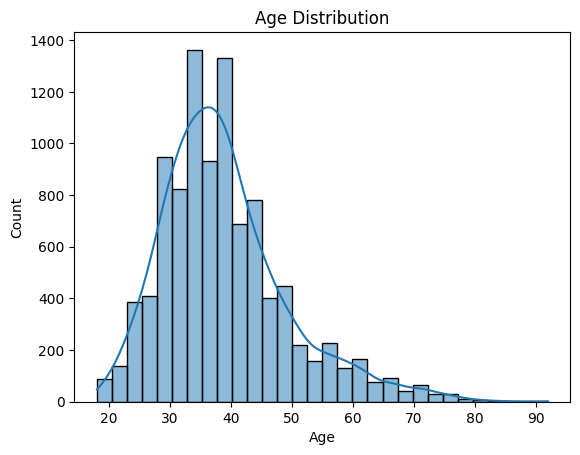

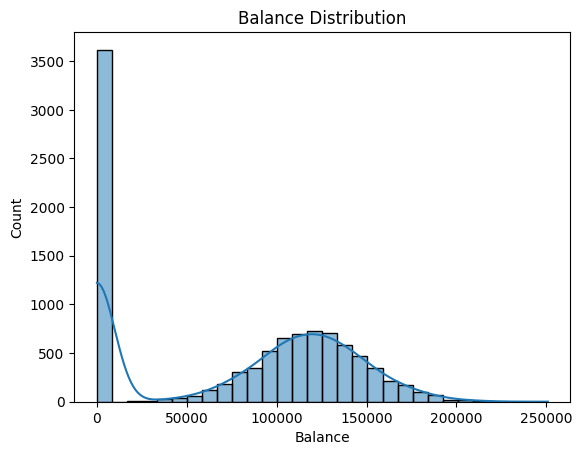

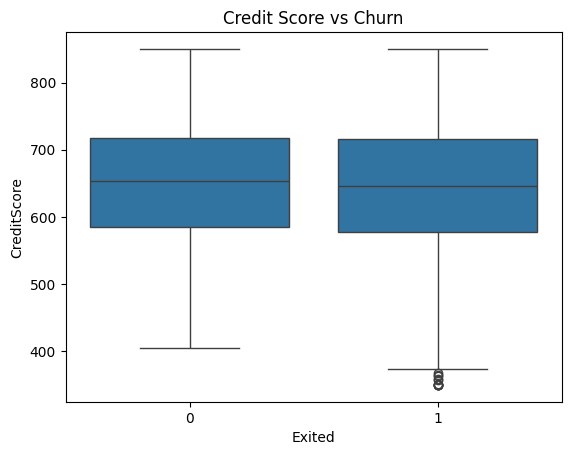

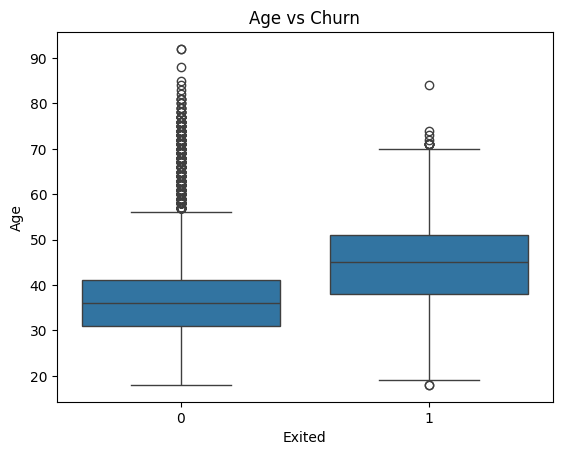

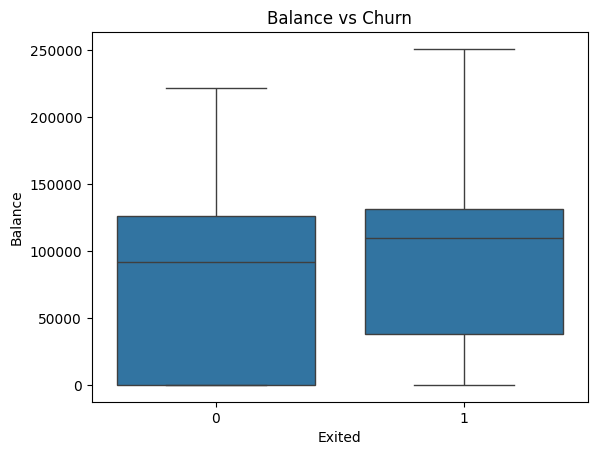

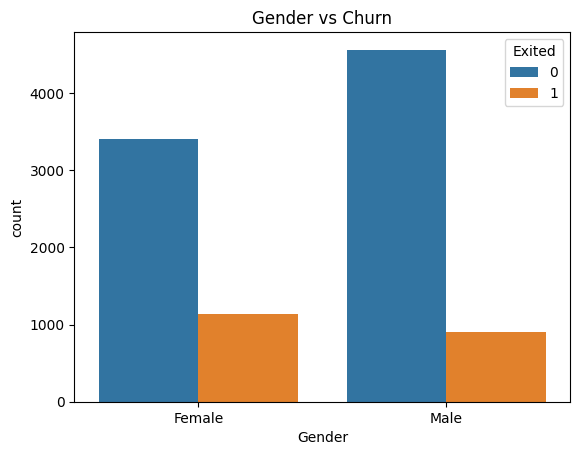

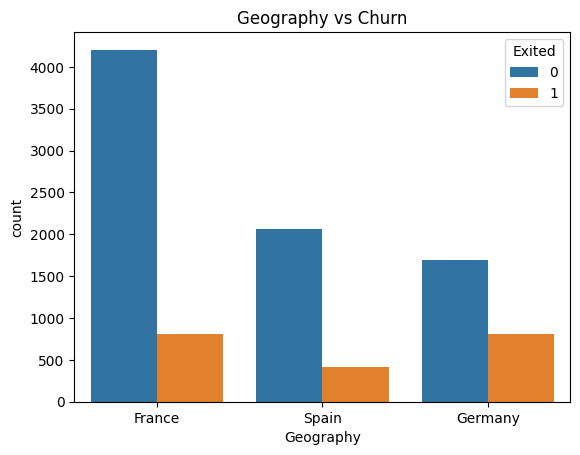

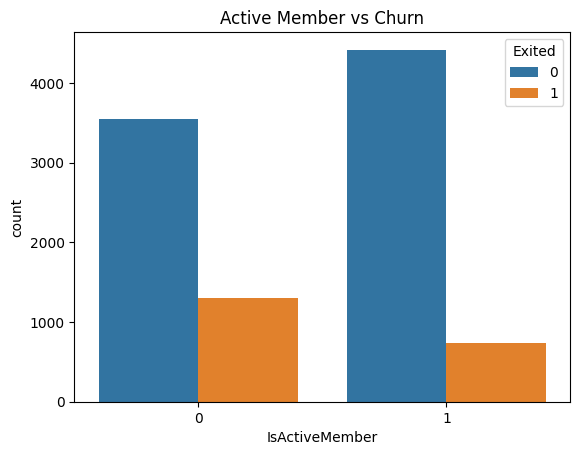

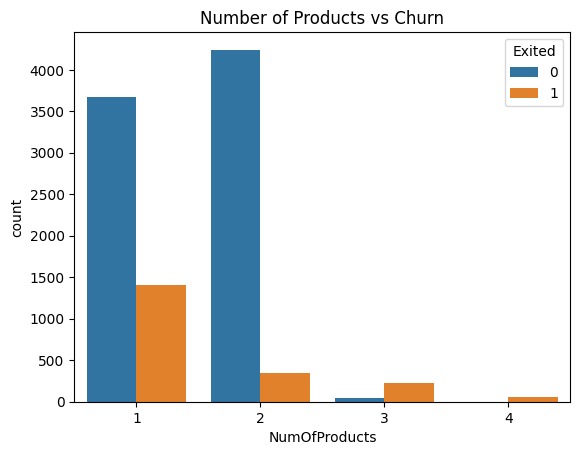

In [ ]:
# ------------------------------
# 2. AGE DISTRIBUTION
# ------------------------------
plt.figure()
sns.histplot(df["Age"], bins=30, kde=True)
plt.title("Age Distribution")
plt.show()

# ------------------------------
# 3. BALANCE DISTRIBUTION
# ------------------------------
plt.figure()
sns.histplot(df["Balance"], bins=30, kde=True)
plt.title("Balance Distribution")
plt.show()

# ------------------------------
# 4. CREDIT SCORE VS CHURN
# ------------------------------
plt.figure()
sns.boxplot(x="Exited", y="CreditScore", data=df)
plt.title("Credit Score vs Churn")
plt.show()

# ------------------------------
# 5. AGE VS CHURN
# ------------------------------
plt.figure()
sns.boxplot(x="Exited", y="Age", data=df)
plt.title("Age vs Churn")
plt.show()

# ------------------------------
# 6. BALANCE VS CHURN
# ------------------------------
plt.figure()
sns.boxplot(x="Exited", y="Balance", data=df)
plt.title("Balance vs Churn")
plt.show()

# ------------------------------
# 7. GENDER VS CHURN
# ------------------------------
plt.figure()
sns.countplot(x="Gender", hue="Exited", data=df)
plt.title("Gender vs Churn")
plt.show()

# ------------------------------
# 8. GEOGRAPHY VS CHURN
# ------------------------------
plt.figure()
sns.countplot(x="Geography", hue="Exited", data=df)
plt.title("Geography vs Churn")
plt.show()

# ------------------------------
# 9. ACTIVE MEMBER VS CHURN
# ------------------------------
plt.figure()
sns.countplot(x="IsActiveMember", hue="Exited", data=df)
plt.title("Active Member vs Churn")
plt.show()

# ------------------------------
# 10. NUM OF PRODUCTS VS CHURN
# ------------------------------
plt.figure()
sns.countplot(x="NumOfProducts", hue="Exited", data=df)
plt.title("Number of Products vs Churn")
plt.show()

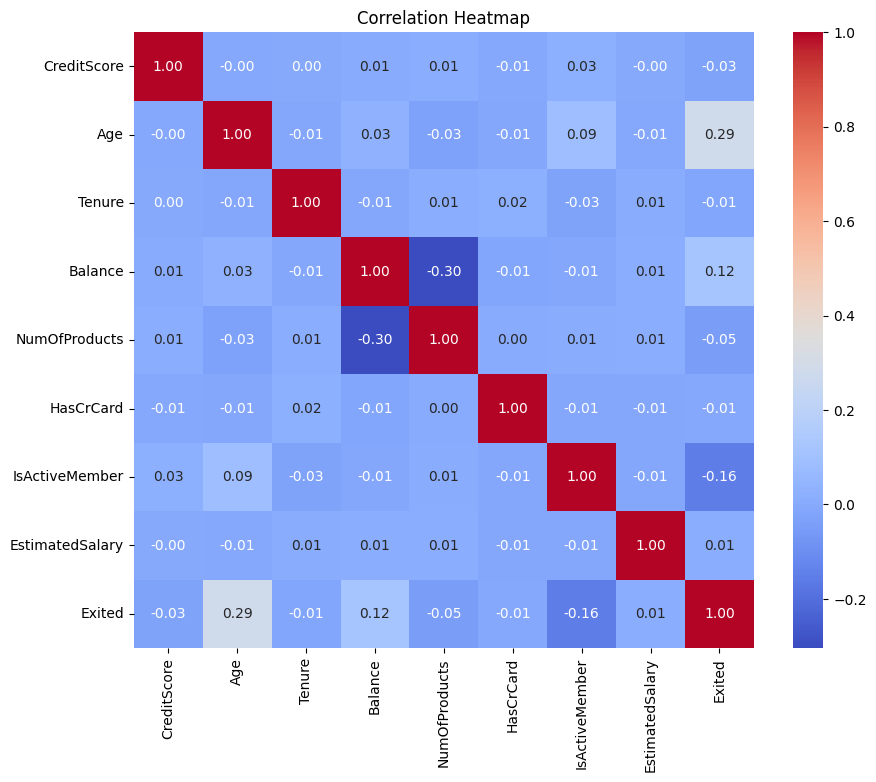

In [ ]:
# ------------------------------
# 11. CORRELATION HEATMAP (FIXED)
# ------------------------------
plt.figure(figsize=(10,8))

numeric_df = df.select_dtypes(include=["int64", "float64"])

sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()

In [ ]:
# ==============================
# 4. FEATURE ENGINEERING
# ==============================
df["Age_Balance"] = df["Age"] * df["Balance"]
df["Tenure_Products"] = df["Tenure"] * df["NumOfProducts"]
df["Active_Balance"] = df["IsActiveMember"] * df["Balance"]
df["Credit_Age"] = df["CreditScore"] * df["Age"]
df["Products_per_Tenure"] = df["NumOfProducts"] / (df["Tenure"] + 1)

df["ChurnRiskScore"] = (
    df["Age"] * 0.3 +
    df["Balance"] * 0.00001 +
    (1 - df["IsActiveMember"]) * 2 +
    df["NumOfProducts"] * -0.5
)


In [ ]:
# ==============================
# 6. ENCODE CATEGORICAL (REQUIRED FOR SMOTE)
# ==============================
df["Gender"] = df["Gender"].map({"Male": 0, "Female": 1})
df["Geography"] = df["Geography"].map({"France": 0, "Spain": 1, "Germany": 2})

In [ ]:
# ==============================
# 7. FEATURES & TARGET
# ==============================
X = df.drop("Exited", axis=1)
y = df["Exited"]

In [ ]:
# ==============================
# 8. SMOTE BEFORE SPLIT ⚠️
# ==============================
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X, y)

# ==============================
# 9. TRAIN TEST SPLIT
# ==============================
X_train, X_test, y_train, y_test = train_test_split(
    X_res, y_res, test_size=0.2, random_state=42
)

In [ ]:
# ==============================
# 10. CATBOOST MODEL
# ==============================
model = CatBoostClassifier(
    iterations=1000,
    depth=6,
    learning_rate=0.03,
    loss_function='Logloss',
    eval_metric='AUC',
    verbose=0,
    random_state=42
)

In [ ]:
# ==============================
# 11. TRAIN
# ==============================
model.fit(X_train, y_train)

# ==============================
# 12. PREDICT
# ==============================
y_probs = model.predict_proba(X_test)[:,1]

# Threshold tuning
best_thresh = 0
best_f1 = 0

for t in np.arange(0.3, 0.6, 0.02):
    preds = (y_probs > t).astype(int)
    f1 = f1_score(y_test, preds)

    if f1 > best_f1:
        best_f1 = f1
        best_thresh = t

print("Best Threshold:", best_thresh)

y_pred = (y_probs > best_thresh).astype(int)


Best Threshold: 0.5200000000000002


In [ ]:
# ==============================
# 13. EVALUATION
# ==============================
print("\n🔥 FINAL MODEL PERFORMANCE 🔥\n")

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))
print("ROC AUC  :", roc_auc_score(y_test, y_pred))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))


🔥 FINAL MODEL PERFORMANCE 🔥

Accuracy : 0.9102322661644695
Precision: 0.9445614035087719
Recall   : 0.866709594333548
F1 Score : 0.9039623908663532
ROC AUC  : 0.9091661872463821

Classification Report:

              precision    recall  f1-score   support

           0       0.88      0.95      0.92      1633
           1       0.94      0.87      0.90      1553

    accuracy                           0.91      3186
   macro avg       0.91      0.91      0.91      3186
weighted avg       0.91      0.91      0.91      3186



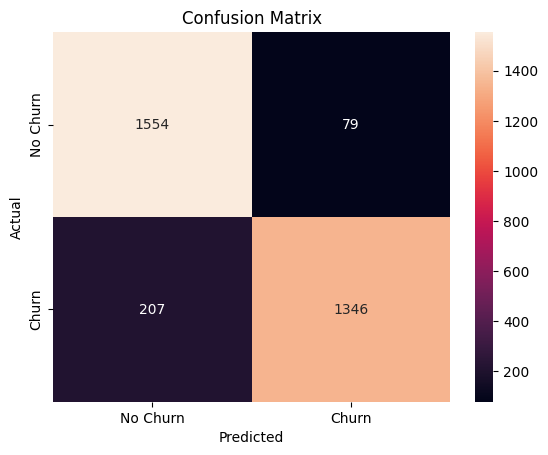

In [ ]:
# ==============================
# 14. CONFUSION MATRIX
# ==============================
cm = confusion_matrix(y_test, y_pred)

plt.figure()
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=["No Churn", "Churn"],
            yticklabels=["No Churn", "Churn"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
model.save_model("churn_model.cbm")

In [ ]:
# !pip install gradio catboost

import gradio as gr
import numpy as np
from catboost import CatBoostClassifier
import random

# ==============================
# LOAD MODEL
# ==============================
model = CatBoostClassifier()
model.load_model("churn_model.cbm")

# ==============================
# PREDICTION FUNCTION
# ==============================
def predict_churn(credit_score, geography, gender, age, tenure,
                  balance, num_products, has_card, is_active, salary):

    geo_map = {"France": 0, "Spain": 1, "Germany": 2}
    gender_map = {"Male": 0, "Female": 1}

    geography = geo_map[geography]
    gender = gender_map[gender]

    # Feature engineering
    age_balance = age * balance
    tenure_products = tenure * num_products
    active_balance = is_active * balance
    credit_age = credit_score * age
    products_per_tenure = num_products / (tenure + 1)

    churn_risk = (
        age * 0.3 +
        balance * 0.00001 +
        (1 - is_active) * 2 +
        num_products * -0.5
    )

    data = np.array([[credit_score, geography, gender, age, tenure,
                      balance, num_products, has_card, is_active, salary,
                      age_balance, tenure_products, active_balance,
                      credit_age, products_per_tenure, churn_risk]])

    prob = model.predict_proba(data)[0][1]

    if prob > 0.5:
        return f"⚠️ Churn (Probability: {prob:.2f})"
    else:
        return f"✅ No Churn (Probability: {prob:.2f})"

# ==============================
# RANDOM INPUT GENERATOR
# ==============================
def generate_random():
    return (
        random.randint(350, 850),                 # credit score
        random.choice(["France", "Spain", "Germany"]),
        random.choice(["Male", "Female"]),
        random.randint(18, 80),                  # age
        random.randint(0, 10),                   # tenure
        round(random.uniform(0, 250000), 2),     # balance
        random.randint(1, 4),                    # products
        random.choice([0, 1]),                   # card
        random.choice([0, 1]),                   # active
        round(random.uniform(10000, 200000), 2)  # salary
    )

# ==============================
# GRADIO BLOCK UI
# ==============================
with gr.Blocks() as demo:
    gr.Markdown("## 🔮 Customer Churn Prediction System")

    with gr.Row():
        credit_score = gr.Number(label="Credit Score")
        geography = gr.Dropdown(["France", "Spain", "Germany"], label="Geography")
        gender = gr.Dropdown(["Male", "Female"], label="Gender")

    with gr.Row():
        age = gr.Number(label="Age")
        tenure = gr.Number(label="Tenure")
        balance = gr.Number(label="Balance")

    with gr.Row():
        num_products = gr.Number(label="Number of Products")
        has_card = gr.Radio([0,1], label="Has Credit Card")
        is_active = gr.Radio([0,1], label="Is Active Member")

    salary = gr.Number(label="Estimated Salary")

    output = gr.Textbox(label="Prediction")

    with gr.Row():
        predict_btn = gr.Button("🔍 Predict")
        random_btn = gr.Button("🎲 Random Input")

    # Button actions
    predict_btn.click(
        predict_churn,
        inputs=[credit_score, geography, gender, age, tenure,
                balance, num_products, has_card, is_active, salary],
        outputs=output
    )

    random_btn.click(
        generate_random,
        inputs=[],
        outputs=[credit_score, geography, gender, age, tenure,
                 balance, num_products, has_card, is_active, salary]
    )

# ==============================
# LAUNCH
# ==============================
demo.launch(debug=True)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://90bbf9e3bad4897fe1.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://90bbf9e3bad4897fe1.gradio.live
